# 睡眠段階に伴う脳波活動の生理学的分析

## 1. 研究目的

睡眠段階によって脳波の周波数成分がどのように変化するのかを分析し、
その背景にある生理学的な仕組みについて考察する。

特に、深いノンレム睡眠（N3）におけるデルタ波の特徴に注目する。

## 2. 仮説

- 仮説①：N3では、他の睡眠段階よりデルタ波の相対パワーが高い。
- 仮説②：N3では、デルタ波が占める割合が高く、周波数構成が他の睡眠段階と異なる。

## 3. 分析方針

1. 睡眠段階ごとのデルタ波の相対パワーを比較する。
2. N3と他の睡眠段階の違いを定量的に評価する。
3. 周波数構成の違いを可視化する。
4. 結果を睡眠生理学の知見と照らし合わせて考察する。

In [1]:
import pandas as pd
from pathlib import Path

# 保存したCSVを読み込む
data_path = Path("../data/processed/sleep_physiology_features.csv")

physiology_df = pd.read_csv(data_path)

# データの基本情報を確認
print("データサイズ:", physiology_df.shape)
print("\n睡眠段階ごとのデータ数:")
print(physiology_df["stage"].value_counts())

display(physiology_df.head())

データサイズ: (721, 7)

睡眠段階ごとのデータ数:
stage
N2     250
N3     220
REM    125
W       68
N1      58
Name: count, dtype: int64


,delta,theta,alpha,beta,stage,epoch,start_sec
0,0.550453,0.277225,0.125416,0.046906,N1,0,30630.0
1,0.591739,0.303730,0.054197,0.050334,N1,1,30660.0
2,0.706459,0.222323,0.040499,0.030719,N1,2,30690.0
3,0.790701,0.175452,0.018826,0.015021,N1,3,30720.0
4,0.836314,0.134410,0.016436,0.012839,N2,4,30750.0


In [2]:
# 睡眠段階ごとのデルタ波の相対パワーを集計
stage_order = ["W", "N1", "N2", "N3", "REM"]

delta_summary = (
    physiology_df
    .groupby("stage")["delta"]
    .agg(["count", "mean", "median", "std"])
    .reindex(stage_order)
)

# 見やすい列名に変更
delta_summary.columns = [
    "データ数",
    "平均値",
    "中央値",
    "標準偏差"
]

display(delta_summary.round(3))

,データ数,平均値,中央値,標準偏差
stage,,,,
W,68,0.726,0.842,0.223
N1,58,0.657,0.660,0.130
N2,250,0.834,0.840,0.053
N3,220,0.930,0.935,0.033
REM,125,0.678,0.674,0.073


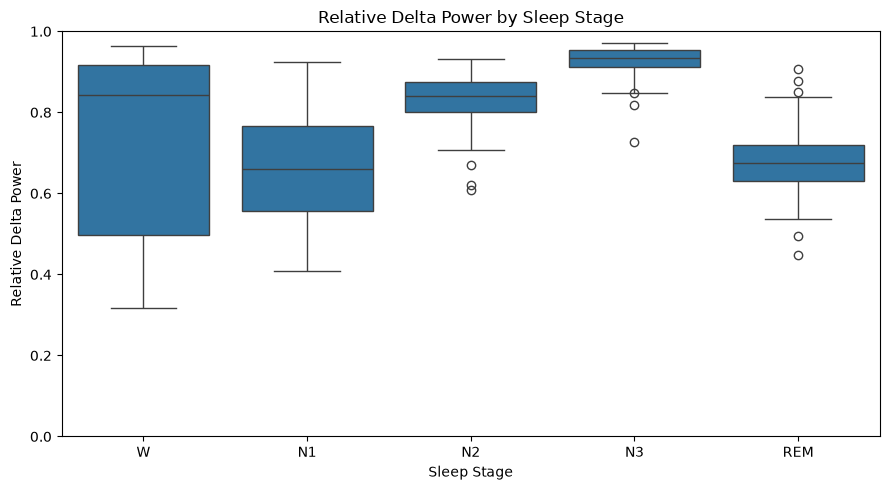

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 睡眠段階ごとのデルタ波の分布
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=physiology_df,
    x="stage",
    y="delta",
    order=stage_order
)

plt.title("Relative Delta Power by Sleep Stage")
plt.xlabel("Sleep Stage")
plt.ylabel("Relative Delta Power")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [4]:
# 各エポックの順番を追加
physiology_df["epoch_index"] = range(len(physiology_df))

display(physiology_df.head())

,delta,theta,alpha,beta,stage,epoch,start_sec,epoch_index
0,0.550453,0.277225,0.125416,0.046906,N1,0,30630.0,0
1,0.591739,0.303730,0.054197,0.050334,N1,1,30660.0,1
2,0.706459,0.222323,0.040499,0.030719,N1,2,30690.0,2
3,0.790701,0.175452,0.018826,0.015021,N1,3,30720.0,3
4,0.836314,0.134410,0.016436,0.012839,N2,4,30750.0,4


In [5]:
# 時間情報を追加したCSVを読み直す
physiology_df = pd.read_csv(
    "../data/processed/sleep_physiology_features.csv"
)

# 時間を「今回の分析区間の開始からの経過時間」に変換
physiology_df["elapsed_hours"] = (
    physiology_df["start_sec"] - physiology_df["start_sec"].min()
) / 3600

print("データサイズ:", physiology_df.shape)
display(physiology_df.head())

データサイズ: (721, 8)


,delta,theta,alpha,beta,stage,epoch,start_sec,elapsed_hours
0,0.550453,0.277225,0.125416,0.046906,N1,0,30630.0,0.000000
1,0.591739,0.303730,0.054197,0.050334,N1,1,30660.0,0.008333
2,0.706459,0.222323,0.040499,0.030719,N1,2,30690.0,0.016667
3,0.790701,0.175452,0.018826,0.015021,N1,3,30720.0,0.025000
4,0.836314,0.134410,0.016436,0.012839,N2,4,30750.0,0.033333


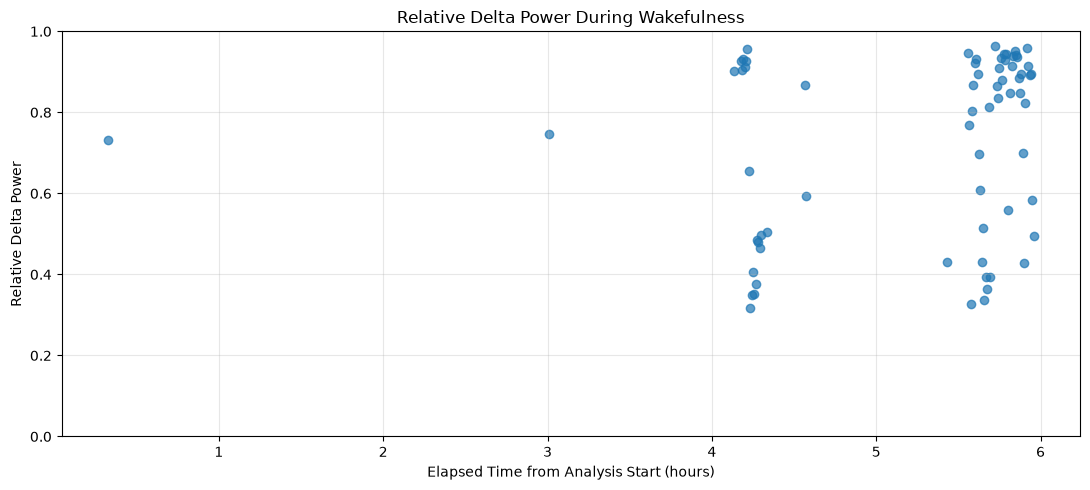

In [6]:
# 覚醒時（W）のデータを抽出
wake_df = physiology_df[
    physiology_df["stage"] == "W"
].copy()

plt.figure(figsize=(11, 5))

plt.scatter(
    wake_df["elapsed_hours"],
    wake_df["delta"],
    alpha=0.7
)

plt.title("Relative Delta Power During Wakefulness")
plt.xlabel("Elapsed Time from Analysis Start (hours)")
plt.ylabel("Relative Delta Power")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# 時間順に並べる
time_df = physiology_df.sort_values("start_sec").copy()

# 直前のエポックの睡眠段階
time_df["previous_stage"] = time_df["stage"].shift(1)

# 直前からWに切り替わったエポックを抽出
wake_transitions = time_df[
    (time_df["stage"] == "W") &
    (time_df["previous_stage"] != "W")
].copy()

# 見やすいように経過時間を追加
wake_transitions["elapsed_hours"] = (
    wake_transitions["start_sec"] - time_df["start_sec"].min()
) / 3600

display(
    wake_transitions[
        ["elapsed_hours", "previous_stage", "stage", "delta"]
    ].round(3)
)

,elapsed_hours,previous_stage,stage,delta
39,0.325,N3,W,0.733
361,3.008,N1,W,0.746
496,4.133,REM,W,0.901
501,4.175,N1,W,0.926
520,4.333,N1,W,0.504
548,4.567,N2,W,0.867
652,5.433,REM,W,0.430
667,5.558,REM,W,0.946
687,5.725,N1,W,0.964
698,5.817,N1,W,0.849


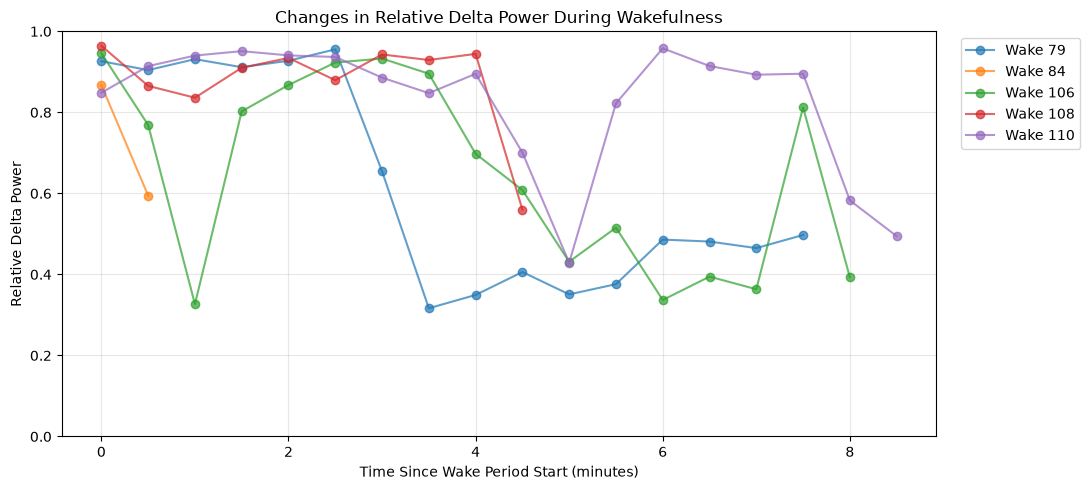

In [8]:
import matplotlib.pyplot as plt

# 時間順に並べる
time_df = physiology_df.sort_values("start_sec").reset_index(drop=True).copy()

# 睡眠段階が切り替わった位置を識別
time_df["stage_group"] = (
    time_df["stage"] != time_df["stage"].shift()
).cumsum()

# 連続した覚醒区間を抽出
wake_df = time_df[time_df["stage"] == "W"].copy()

plt.figure(figsize=(11, 5))

for group_id, group in wake_df.groupby("stage_group"):
    if len(group) >= 2:
        # 各覚醒区間の開始からの経過時間（分）
        minutes = (
            group["start_sec"] - group["start_sec"].iloc[0]
        ) / 60

        plt.plot(
            minutes,
            group["delta"],
            marker="o",
            alpha=0.7,
            label=f"Wake {group_id}"
        )

plt.title("Changes in Relative Delta Power During Wakefulness")
plt.xlabel("Time Since Wake Period Start (minutes)")
plt.ylabel("Relative Delta Power")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

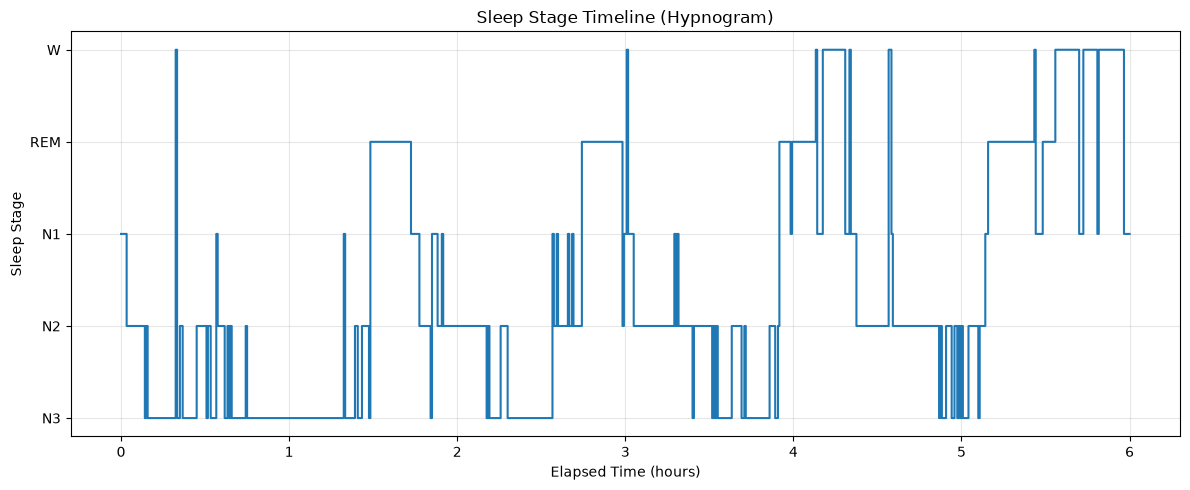

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# 睡眠段階を数値に変換
stage_map = {
    "W": 4,
    "REM": 3,
    "N1": 2,
    "N2": 1,
    "N3": 0
}

# 時間順に並べる
sleep_timeline = physiology_df.sort_values("start_sec").copy()

# 睡眠段階を数値化
sleep_timeline["stage_num"] = sleep_timeline["stage"].map(stage_map)

# 分析開始からの経過時間（時間）
sleep_timeline["elapsed_hours"] = (
    sleep_timeline["start_sec"]
    - sleep_timeline["start_sec"].min()
) / 3600

# グラフ作成
plt.figure(figsize=(12, 5))

plt.step(
    sleep_timeline["elapsed_hours"],
    sleep_timeline["stage_num"],
    where="post"
)

plt.yticks(
    [0, 1, 2, 3, 4],
    ["N3", "N2", "N1", "REM", "W"]
)

plt.xlabel("Elapsed Time (hours)")
plt.ylabel("Sleep Stage")
plt.title("Sleep Stage Timeline (Hypnogram)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

# 睡眠段階の順序
stage_order = ["W", "N1", "N2", "N3", "REM"]

# エポック順に並べる
sleep_df = (
    physiology_df[["epoch", "stage"]]
    .sort_values("epoch")
    .reset_index(drop=True)
    .copy()
)

# 次のエポックの睡眠段階
sleep_df["next_stage"] = sleep_df["stage"].shift(-1)

# 睡眠段階が変化した箇所だけ抽出
transitions = sleep_df[
    sleep_df["next_stage"].notna()
    & (sleep_df["stage"] != sleep_df["next_stage"])
].copy()

# 遷移回数を集計
transition_table = pd.crosstab(
    transitions["stage"],
    transitions["next_stage"]
).reindex(
    index=stage_order,
    columns=stage_order,
    fill_value=0
)

print("睡眠段階の切り替わり総数：", len(transitions))

display(transition_table)

睡眠段階の切り替わり総数： 110


next_stage,W,N1,N2,N3,REM
stage,,,,,
W,0,9,0,1,0
N1,5,0,14,1,3
N2,1,8,0,29,2
N3,1,4,25,0,1
REM,3,2,1,0,0


In [11]:
# N2 → N3 の移行箇所を抽出
n2_to_n3 = transitions[
    (transitions["stage"] == "N2") &
    (transitions["next_stage"] == "N3")
].copy()

print("N2 → N3 の移行回数：", len(n2_to_n3))

# 移行が起きたエポック番号を確認
display(n2_to_n3[["epoch", "stage", "next_stage"]].head(10))

N2 → N3 の移行回数： 29


,epoch,stage,next_stage
16,16,N2,N3
18,18,N2,N3
43,43,N2,N3
60,60,N2,N3
63,63,N2,N3
73,73,N2,N3
76,76,N2,N3
78,78,N2,N3
89,89,N2,N3
168,168,N2,N3


,epoch,N2_delta,N3_delta,change
0,16,0.862,0.849,-0.013
1,18,0.841,0.847,0.006
2,43,0.899,0.897,-0.002
3,60,0.796,0.873,0.078
4,63,0.859,0.880,0.021
5,73,0.888,0.899,0.011
6,76,0.886,0.906,0.020
7,78,0.862,0.927,0.065
8,89,0.933,0.916,-0.017
9,168,0.878,0.902,0.024


比較できた移行回数： 29
デルタ波が増加した割合： 75.9 %


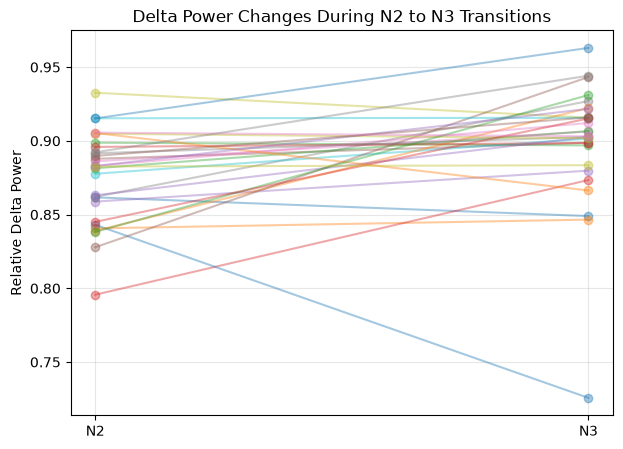

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# エポック番号を使ってデルタ波を参照
delta_by_epoch = physiology_df.set_index("epoch")["delta"]

# N2 → N3 の移行前後を取得
transition_comparison = []

for epoch in n2_to_n3["epoch"]:

    before = delta_by_epoch.get(epoch)
    after = delta_by_epoch.get(epoch + 1)

    if pd.notna(before) and pd.notna(after):

        transition_comparison.append({
            "epoch": epoch,
            "N2_delta": before,
            "N3_delta": after,
            "change": after - before
        })

transition_comparison_df = pd.DataFrame(transition_comparison)

# 結果を表示
display(transition_comparison_df.head(10).round(3))

print("比較できた移行回数：", len(transition_comparison_df))

print(
    "デルタ波が増加した割合：",
    round(
        (transition_comparison_df["change"] > 0).mean() * 100,
        1
    ),
    "%"
)

# グラフ
plt.figure(figsize=(7, 5))

for _, row in transition_comparison_df.iterrows():

    plt.plot(
        ["N2", "N3"],
        [row["N2_delta"], row["N3_delta"]],
        marker="o",
        alpha=0.4
    )

plt.ylabel("Relative Delta Power")
plt.title("Delta Power Changes During N2 to N3 Transitions")

plt.grid(alpha=0.3)
plt.show()

In [13]:
# デルタ波の変化を分類
increase = (transition_comparison_df["change"] > 0).sum()
decrease = (transition_comparison_df["change"] < 0).sum()
no_change = (transition_comparison_df["change"] == 0).sum()

total = len(transition_comparison_df)

print("【N2 → N3 のデルタ波変化】")
print(f"増加：{increase}回（{increase / total * 100:.1f}%）")
print(f"減少：{decrease}回（{decrease / total * 100:.1f}%）")
print(f"変化なし：{no_change}回（{no_change / total * 100:.1f}%）")

print("\n【変化量の統計】")
print(f"平均変化量：{transition_comparison_df['change'].mean():.4f}")
print(f"中央値：{transition_comparison_df['change'].median():.4f}")
print(f"標準偏差：{transition_comparison_df['change'].std():.4f}")

【N2 → N3 のデルタ波変化】
増加：22回（75.9%）
減少：7回（24.1%）
変化なし：0回（0.0%）

【変化量の統計】
平均変化量：0.0230
中央値：0.0210
標準偏差：0.0449


In [14]:
# N3 → N2 の移行箇所を抽出
n3_to_n2 = transitions[
    (transitions["stage"] == "N3") &
    (transitions["next_stage"] == "N2")
].copy()

# 移行前後のデルタ波を比較
reverse_comparison = []

for epoch in n3_to_n2["epoch"]:

    before = delta_by_epoch.get(epoch)
    after = delta_by_epoch.get(epoch + 1)

    if pd.notna(before) and pd.notna(after):

        reverse_comparison.append({
            "epoch": epoch,
            "N3_delta": before,
            "N2_delta": after,
            "change": after - before
        })

reverse_comparison_df = pd.DataFrame(reverse_comparison)

# 増加・減少を集計
increase = (reverse_comparison_df["change"] > 0).sum()
decrease = (reverse_comparison_df["change"] < 0).sum()
total = len(reverse_comparison_df)

print("【N3 → N2 のデルタ波変化】")
print(f"移行回数：{total}")
print(f"増加：{increase}回（{increase / total * 100:.1f}%）")
print(f"減少：{decrease}回（{decrease / total * 100:.1f}%）")

print("\n【変化量の統計】")
print(f"平均変化量：{reverse_comparison_df['change'].mean():.4f}")
print(f"中央値：{reverse_comparison_df['change'].median():.4f}")
print(f"標準偏差：{reverse_comparison_df['change'].std():.4f}")

display(reverse_comparison_df.head(10).round(3))

【N3 → N2 のデルタ波変化】
移行回数：25
増加：3回（12.0%）
減少：22回（88.0%）

【変化量の統計】
平均変化量：-0.0389
中央値：-0.0288
標準偏差：0.0450


,epoch,N3_delta,N2_delta,change
0,17,0.849,0.841,-0.008
1,41,0.901,0.871,-0.031
2,53,0.947,0.832,-0.115
3,61,0.873,0.832,-0.041
4,75,0.878,0.886,0.008
5,77,0.906,0.862,-0.044
6,88,0.904,0.933,0.029
7,166,0.908,0.873,-0.035
8,171,0.860,0.774,-0.086
9,261,0.907,0.896,-0.011


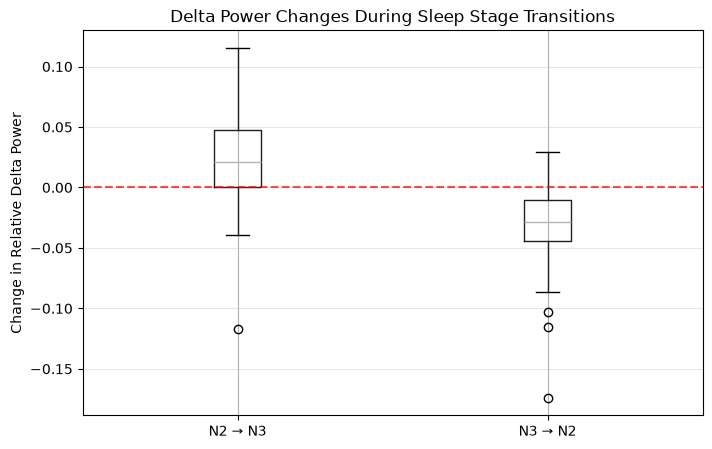

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# 2種類の移行データを結合
comparison_df = pd.DataFrame({
    "N2 → N3": transition_comparison_df["change"],
    "N3 → N2": reverse_comparison_df["change"]
})

# 箱ひげ図
plt.figure(figsize=(8, 5))

comparison_df.boxplot()

# 変化なしの基準線
plt.axhline(0, color="red", linestyle="--", alpha=0.7)

plt.ylabel("Change in Relative Delta Power")
plt.title("Delta Power Changes During Sleep Stage Transitions")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [16]:
import pandas as pd

# 既存のデータをコピー
sleep_comparison_df = physiology_df.copy()

# エポック番号順に並べる
sleep_comparison_df = sleep_comparison_df.sort_values("epoch")

# 記録を前半・後半に分割
midpoint = len(sleep_comparison_df) // 2

sleep_comparison_df["period"] = (
    ["First Half"] * midpoint
    + ["Second Half"] * (len(sleep_comparison_df) - midpoint)
)

# 各睡眠段階の割合を計算
stage_percentage = pd.crosstab(
    sleep_comparison_df["period"],
    sleep_comparison_df["stage"],
    normalize="index"
) * 100

# 睡眠段階の順番を統一
stage_percentage = stage_percentage.reindex(
    columns=["W", "N1", "N2", "N3", "REM"],
    fill_value=0
)

print("睡眠前半・後半の睡眠段階の割合（%）")
display(stage_percentage.round(1))

睡眠前半・後半の睡眠段階の割合（%）


stage,W,N1,N2,N3,REM
period,,,,,
First Half,0.3,6.1,29.4,48.1,16.1
Second Half,18.6,10.0,39.9,13.0,18.6


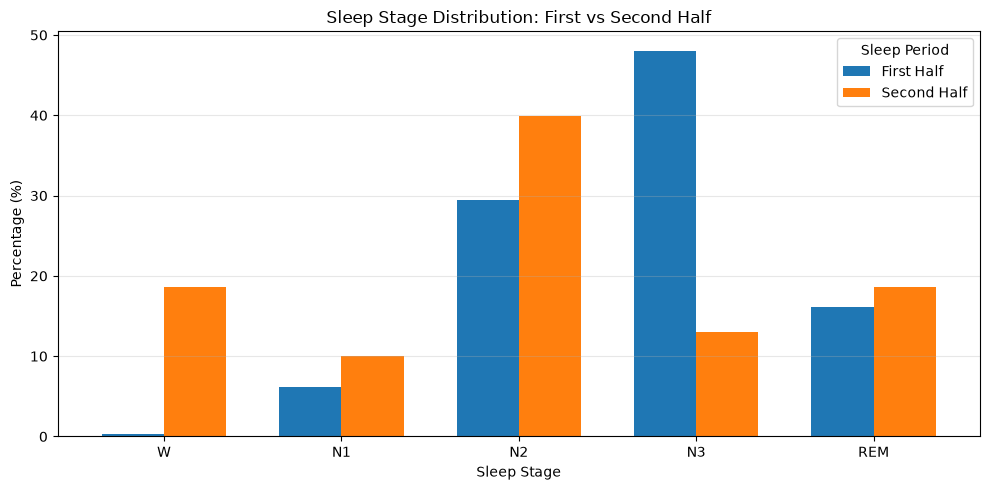

In [17]:
import matplotlib.pyplot as plt

# 睡眠段階の割合を棒グラフで比較
ax = stage_percentage.T.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

plt.title("Sleep Stage Distribution: First vs Second Half")
plt.xlabel("Sleep Stage")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Sleep Period")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# 睡眠段階が変化する位置を特定
sleep_duration_df = physiology_df.copy()

sleep_duration_df = sleep_duration_df.sort_values("epoch")

# 睡眠段階が切り替わるたびにグループ番号を付ける
sleep_duration_df["group"] = (
    sleep_duration_df["stage"]
    != sleep_duration_df["stage"].shift()
).cumsum()

# 各グループの継続時間を計算
duration_df = (
    sleep_duration_df
    .groupby("group")
    .agg(
        stage=("stage", "first"),
        epochs=("epoch", "count")
    )
    .reset_index(drop=True)
)

# 1エポック = 30秒
duration_df["duration_min"] = duration_df["epochs"] * 0.5

# 睡眠段階ごとの継続時間を集計
duration_summary = (
    duration_df
    .groupby("stage")["duration_min"]
    .agg(["count", "mean", "median", "max"])
    .reindex(["W", "N1", "N2", "N3", "REM"])
)

print("睡眠段階ごとの連続時間（分）")
display(duration_summary.round(2))

睡眠段階ごとの連続時間（分）


,count,mean,median,max
stage,,,,
W,10,3.40,0.75,9.0
N1,24,1.21,0.75,3.0
N2,40,3.12,1.25,16.5
N3,31,3.55,1.00,34.5
REM,6,10.42,11.50,16.5


In [19]:
# N3の連続区間を抽出
n3_duration = (
    sleep_duration_df[sleep_duration_df["stage"] == "N3"]
    .groupby("group")
    .agg(
        start_epoch=("epoch", "min"),
        epochs=("epoch", "count")
    )
    .reset_index(drop=True)
)

# 継続時間を分に変換
n3_duration["duration_min"] = n3_duration["epochs"] * 0.5

# 分析区間の前半・後半に分類
mid_epoch = len(sleep_duration_df) // 2

n3_duration["period"] = n3_duration["start_epoch"].apply(
    lambda x: "First Half" if x < mid_epoch else "Second Half"
)

# 前半・後半で継続時間を比較
n3_summary = (
    n3_duration
    .groupby("period")["duration_min"]
    .agg(["count", "mean", "median", "max"])
)

print("N3の連続時間：前半・後半比較")
display(n3_summary.round(2))

N3の連続時間：前半・後半比較


,count,mean,median,max
period,,,,
First Half,17,5.09,1.50,34.5
Second Half,14,1.68,0.75,8.5


In [20]:
# N3区間を継続時間の長い順に表示
display(
    n3_duration[
        ["start_epoch", "duration_min", "period"]
    ]
    .sort_values("duration_min", ascending=False)
    .reset_index(drop=True)
)

,start_epoch,duration_min,period
0,90,34.5,First Half
1,276,16.0,First Half
2,19,10.0,First Half
3,446,8.5,Second Half
4,426,5.0,Second Half
5,79,5.0,First Half
6,44,5.0,First Half
7,263,4.0,First Half
8,160,3.5,First Half
9,64,2.0,First Half


,start_epoch,duration_min,mean_delta
9,90,34.5,0.952
16,276,16.0,0.948
1,19,10.0,0.914
22,446,8.5,0.938
20,426,5.0,0.922
8,79,5.0,0.919
3,44,5.0,0.912
15,263,4.0,0.925
10,160,3.5,0.885
5,64,2.0,0.880


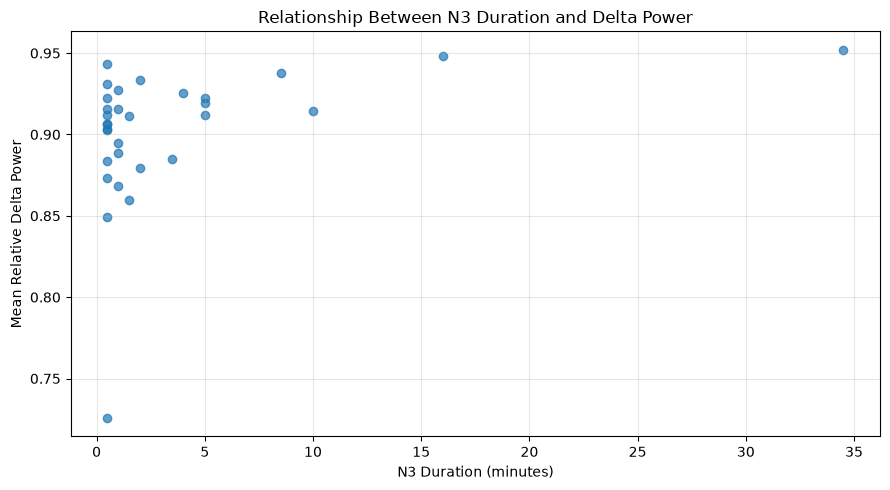

継続時間とデルタ波の相関係数：0.361


In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# N3のデータだけを抽出
n3_epochs = sleep_duration_df[
    sleep_duration_df["stage"] == "N3"
].copy()

# 各N3区間の継続時間とデルタ波を集計
n3_power_duration = (
    n3_epochs
    .groupby("group")
    .agg(
        start_epoch=("epoch", "min"),
        epochs=("epoch", "count"),
        mean_delta=("delta", "mean")
    )
    .reset_index(drop=True)
)

# 継続時間を分に変換
n3_power_duration["duration_min"] = (
    n3_power_duration["epochs"] * 0.5
)

# 結果を確認
display(
    n3_power_duration[
        ["start_epoch", "duration_min", "mean_delta"]
    ]
    .sort_values("duration_min", ascending=False)
    .head(10)
    .round(3)
)

# 散布図
plt.figure(figsize=(9, 5))

plt.scatter(
    n3_power_duration["duration_min"],
    n3_power_duration["mean_delta"],
    alpha=0.7
)

plt.xlabel("N3 Duration (minutes)")
plt.ylabel("Mean Relative Delta Power")
plt.title("Relationship Between N3 Duration and Delta Power")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 相関係数
correlation = n3_power_duration[
    ["duration_min", "mean_delta"]
].corr().iloc[0, 1]

print(f"継続時間とデルタ波の相関係数：{correlation:.3f}")

## 結果と考察

### 1. 睡眠段階の移行とデルタ波の変化

N2からN3への移行は29回確認され、そのうち22回（75.9%）でデルタ波の相対パワーが増加した。平均変化量は+0.0230であった。

一方、N3からN2への移行では、デルタ波の相対パワーの平均変化量は-0.0389となった。

この結果から、今回のデータでは、N3への移行に伴ってデルタ波の割合が増加し、N3からN2への移行では減少する傾向が確認された。

### 2. 睡眠前半・後半の比較

睡眠前半ではN3の割合が48.1%だったのに対し、後半では13.0%に減少した。

また、覚醒（W）の割合は前半の0.3%から後半の18.6%に増加した。

今回の記録では、睡眠前半に深い睡眠が多く、後半になるにつれて覚醒が増える傾向が見られた。

### 3. N3の継続時間とデルタ波の関係

N3の継続時間と平均デルタ波相対パワーの相関係数は0.361であり、弱い正の相関が見られた。

ただし、継続時間の短い区間が多く、一部の長い区間が相関係数に影響している可能性があるため、明確な関係があるとは判断できない。

### 4. まとめ

今回の分析では、睡眠段階の移行や時間経過に伴うデルタ波の変化を確認できた。

これらの結果から、睡眠段階の特徴を捉えるには、周波数成分だけでなく、時間的な変化にも注目することが有用だと考えられる。

ただし、今回の分析は限られた記録を対象としているため、ほかの被験者や記録でも同様の傾向が見られるかは、今後の検証が必要である。